# Final animal phylogenies

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from Bio import SeqIO

# UBA7

In [2]:
file = "final_metazoa_phylogenies/UBA7/13884_UBA7_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

In [20]:
df[df['bits'] > 700].shape

(2744, 29)

In [21]:
df[df['bits'] > 700]['phylum'].value_counts().head(20)

phylum
Chordata           2094
Arthropoda          516
Mollusca             58
Platyhelminthes      34
Cnidaria             14
Echinodermata         9
Annelida              5
Nematoda              3
Tardigrada            3
Rotifera              2
Porifera              2
Placozoa              2
Hemichordata          1
Brachiopoda           1
Name: count, dtype: int64

In [22]:
df[df['bits'] > 700]['protein_name'].value_counts().head(10)

protein_name
ubiquitin-like modifier-activating enzyme 1               603
ubiquitin-like modifier-activating enzyme 1 isoform X1    182
ubiquitin-like modifier-activating enzyme 7 isoform X2    168
ubiquitin-like modifier-activating enzyme 1 isoform X2    166
UBA1                                                      160
ubiquitin-like modifier-activating enzyme 7 isoform X1    156
UBA7                                                      148
ubiquitin-like modifier-activating enzyme 7 isoform X3    121
unnamed protein product                                    87
ubiquitin-like modifier-activating enzyme 7 isoform X4     84
Name: count, dtype: int64

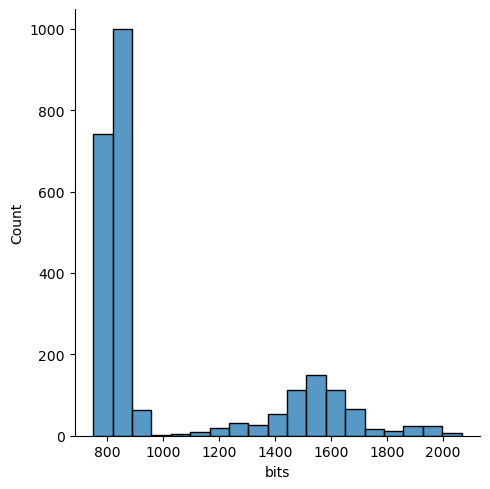

In [17]:
sns.displot(df[(df['bits'] > 750)], x='bits')

In [23]:
# make a FASTA file
bitscore = 700
#hits_number = df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].shape[0]
hits_number = df[(df['bits'] > bitscore)].shape[0]

fasta_file = f"final_metazoa_phylogenies/UBA7/{hits_number}_UBA7_metazoa_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    #for i, row in df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].sort_values(by='bits', ascending=False).iterrows():
    for i, row in df[(df['bits'] > bitscore)].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# SHISA5

In [39]:
file = "final_metazoa_phylogenies/SHISA5/2281_SHISA5_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

In [40]:
df['protein_name']

0                                SHISA5
3                                SHISA5
2                                SHISA5
1            protein shisa-5 isoform X1
4            protein shisa-5 isoform X2
                     ...               
2275    protein shisa-4-like isoform X2
2277               protein shisa-4-like
2278         protein shisa-4 isoform X3
2279            protein shisa-2 homolog
2280         PREDICTED: protein shisa-4
Name: protein_name, Length: 2275, dtype: object

In [20]:
df.columns

Index(['query', 'target', 'fident', 'alnlen', 'mismatch', 'gapopen', 'qstart',
       'qend', 'qcov', 'qlen', 'tstart', 'tend', 'tcov', 'tlen', 'evalue',
       'bits', 'source', 'domain', 'kingdom', 'phylum', 'class', 'order',
       'family', 'genus', 'species', 'protein_name', 'protein_sequence',
       'gene'],
      dtype='object')

In [41]:
file_ensembl = "provisional_ensembl_phylogenies/SHISA2_SHISA3_SHISA4_SHISA5_SHISA6_SHISA7_SHISA8_SHISA9_SHISAL1_SHISAL2A_SHISAL2B/SHISA2_SHISA3_SHISA4_SHISA5_SHISA6_SHISA7_SHISA8_SHISA9_SHISAL1_SHISAL2A_SHISAL2B_ensembl_master_table.csv"
df_ensembl = pd.read_csv(file_ensembl)

file_annotation = "provisional_ensembl_phylogenies/SHISA2_SHISA3_SHISA4_SHISA5_SHISA6_SHISA7_SHISA8_SHISA9_SHISAL1_SHISAL2A_SHISAL2B/SHISA2_SHISA3_SHISA4_SHISA5_SHISA6_SHISA7_SHISA8_SHISA9_SHISAL1_SHISAL2A_SHISAL2B_ensembl_master_table_annotation.tsv"
df_annotation = pd.read_csv(file_annotation, sep='\t')

# Curated fasta file with gene tree sequences
fasta_file = "provisional_ensembl_phylogenies/SHISA2_SHISA3_SHISA4_SHISA5_SHISA6_SHISA7_SHISA8_SHISA9_SHISAL1_SHISAL2A_SHISAL2B/1481_SHISA_ensembl_curated.fasta"
fasta_ids = [record.id for record in SeqIO.parse(fasta_file, "fasta")]
df_ensembl = df_ensembl[df_ensembl['protein_id'].isin(fasta_ids)].copy()
df_ensembl.drop(columns=['species'], inplace=True)

# Taxonomy annotation
df_ensembl = df_ensembl.merge(df_annotation[['protein_id','phylum','class','order','family','genus', 'species']], on='protein_id', how='left')
df_ensembl['domain'] = 'Eukaryota'
df_ensembl['kingdom'] = 'Metazoa'
df_ensembl['gene_name'] = df_ensembl['gene_name'].where(df_ensembl['gene_name'].isna(), df_ensembl['gene_name'].str.upper())

In [42]:
# Filter df_ensembl to only records where protein_seq is not in df's protein_sequence
existing_sequences = set(df['protein_sequence'].dropna())

mask = ~df_ensembl['protein_seq'].isin(existing_sequences)
df_ensembl_new = df_ensembl[mask].copy()

# Rename columns to match df's schema
df_ensembl_new = df_ensembl_new.rename(columns={
    'protein_seq': 'protein_sequence',
    'gene_name': 'protein_name',
    'protein_id': 'target'
})

# Keep only columns that exist in df, reindex to full df schema
common_cols = [col for col in df.columns if col in df_ensembl_new.columns]
df_ensembl_aligned = df_ensembl_new[common_cols].reindex(columns=df.columns)

# Append to df
df = pd.concat([df, df_ensembl_aligned], ignore_index=True)

In [43]:
df

,query,target,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,kingdom,phylum,class,order,family,genus,species,protein_name,protein_sequence,gene
0,ENSP00000296444.2-SHISA5,ENSP00000296444.2,1.000,240.0,0.0,0.0,1.0,240.0,1.0,240.0,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Homo,Homo sapiens,SHISA5,MTAPVPAPRILLPLLLLLLLTPPPGARGEVCMASRGLSLFPESCPD...,SHISA5
1,ENSP00000296444.2-SHISA5,ENSPTRP00000082643.1,0.963,248.0,9.0,0.0,1.0,240.0,1.0,240.0,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Pan,Pan troglodytes,SHISA5,MTAPVPAPRILLPLLLLLLLTPPPGARGEVCMASRGLSLFPESCPD...,SHISA5
2,ENSP00000296444.2-SHISA5,ENSPPAP00000005440.1,0.963,247.0,9.0,0.0,1.0,240.0,1.0,240.0,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Pan,Pan paniscus,SHISA5,MTAPVPAPRILLPLLLLLLLTPPPGARGEVCMASRGLSLFPESCPD...,SHISA5
3,ENSP00000296444.2-SHISA5,XP_018879019.2,0.987,240.0,3.0,0.0,1.0,240.0,1.0,240.0,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Gorilla,Gorilla gorilla,protein shisa-5 isoform X1,MTAPVPAPRILLPLLLLLLLPPPPGARGEVCMASRGLSLFPESCPD...,SHISA5
4,ENSP00000296444.2-SHISA5,XP_008969969.1,0.987,240.0,3.0,0.0,1.0,240.0,1.0,240.0,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Pan,Pan paniscus,protein shisa-5 isoform X2,MTAPVPAPRILLPLLLLLLLTPPPGARGEVCMASRGLSLFPESCPD...,SHISA5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3475,NaN,ENSDARP00000069025.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Metazoa,Chordata,Actinopteri,Cypriniformes,Danionidae,Danio,Danio rerio,SHISA9B,MAVMFLMEICVLTLHDKRHTTTLSFSVRSTVAKKRREERRMKSTGL...,NaN
3476,NaN,ENSAPOP00000014051.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Metazoa,Chordata,Actinopteri,NaN,Pomacentridae,Acanthochromis,Acanthochromis polyacanthus,SHISA9A,MRGKYFLLGFLLLKLMALVCKADGEPGLLGGFVMITTSNGSREEES...,NaN
3477,NaN,ENSBSLP00000007368.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Metazoa,Chordata,Actinopteri,Anabantiformes,Osphronemidae,Betta,Betta splendens,NaN,MASSTQPLLASFSLAMLLGLTSLRGLSSSSLGQVLAQISSNNQTTE...,NaN
3478,NaN,ENSOJAP00000033689.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Metazoa,Chordata,Actinopteri,Beloniformes,Adrianichthyidae,Oryzias,Oryzias javanicus,NaN,MVTVPLPLLINFSLALFLALTTLSGLNLRLSGQAMAQVVSNNQTSQ...,NaN


In [44]:
df['source'].fillna('ensembl_outgroup', inplace=True)

In [45]:
df['source'].value_counts()

source
nr                  1998
ensembl_outgroup    1205
ensembl              277
Name: count, dtype: int64

In [49]:
df

,query,target,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,kingdom,phylum,class,order,family,genus,species,protein_name,protein_sequence,gene
0,ENSP00000296444.2-SHISA5,ENSP00000296444.2,1.000,240.0,0.0,0.0,1.0,240.0,1.0,240.0,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Homo,Homo sapiens,SHISA5,MTAPVPAPRILLPLLLLLLLTPPPGARGEVCMASRGLSLFPESCPD...,SHISA5
1,ENSP00000296444.2-SHISA5,ENSPTRP00000082643.1,0.963,248.0,9.0,0.0,1.0,240.0,1.0,240.0,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Pan,Pan troglodytes,SHISA5,MTAPVPAPRILLPLLLLLLLTPPPGARGEVCMASRGLSLFPESCPD...,SHISA5
2,ENSP00000296444.2-SHISA5,ENSPPAP00000005440.1,0.963,247.0,9.0,0.0,1.0,240.0,1.0,240.0,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Pan,Pan paniscus,SHISA5,MTAPVPAPRILLPLLLLLLLTPPPGARGEVCMASRGLSLFPESCPD...,SHISA5
3,ENSP00000296444.2-SHISA5,XP_018879019.2,0.987,240.0,3.0,0.0,1.0,240.0,1.0,240.0,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Gorilla,Gorilla gorilla,protein shisa-5 isoform X1,MTAPVPAPRILLPLLLLLLLPPPPGARGEVCMASRGLSLFPESCPD...,SHISA5
4,ENSP00000296444.2-SHISA5,XP_008969969.1,0.987,240.0,3.0,0.0,1.0,240.0,1.0,240.0,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Pan,Pan paniscus,protein shisa-5 isoform X2,MTAPVPAPRILLPLLLLLLLTPPPGARGEVCMASRGLSLFPESCPD...,SHISA5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3475,NaN,ENSDARP00000069025.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Metazoa,Chordata,Actinopteri,Cypriniformes,Danionidae,Danio,Danio rerio,SHISA9B,MAVMFLMEICVLTLHDKRHTTTLSFSVRSTVAKKRREERRMKSTGL...,NaN
3476,NaN,ENSAPOP00000014051.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Metazoa,Chordata,Actinopteri,NaN,Pomacentridae,Acanthochromis,Acanthochromis polyacanthus,SHISA9A,MRGKYFLLGFLLLKLMALVCKADGEPGLLGGFVMITTSNGSREEES...,NaN
3477,NaN,ENSBSLP00000007368.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Metazoa,Chordata,Actinopteri,Anabantiformes,Osphronemidae,Betta,Betta splendens,NaN,MASSTQPLLASFSLAMLLGLTSLRGLSSSSLGQVLAQISSNNQTTE...,NaN
3478,NaN,ENSOJAP00000033689.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Metazoa,Chordata,Actinopteri,Beloniformes,Adrianichthyidae,Oryzias,Oryzias javanicus,NaN,MVTVPLPLLINFSLALFLALTTLSGLNLRLSGQAMAQVVSNNQTSQ...,NaN


In [46]:
df.to_csv("final_metazoa_phylogenies/SHISA5/3480_SHISA_metazoa_ensembl_mmseqs.tsv", index=False, sep='\t')

In [48]:
df[[
    'target', 'query', 'fident', 'alnlen', 'mismatch', 'gapopen', 'qstart',
    'qend', 'qcov', 'qlen', 'tstart', 'tend', 'tcov', 'tlen', 'evalue',
    'bits', 'source', 'domain', 'kingdom', 'phylum', 'class', 'order',
    'family', 'genus', 'species', 'protein_name', 'gene'
]].to_csv("final_metazoa_phylogenies/SHISA5/3480_SHISA_metazoa_ensembl_mmseqs_annotation.tsv", index=False, sep='\t')

In [50]:
# make a FASTA file
fasta_file = f"final_metazoa_phylogenies/SHISA5/3480_SHISA_metazoa_mmseqs_foldseek_0_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df.sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# TMEM140

In [ ]:
file = "final_metazoa_phylogenies/TMEM140/781_TMEM140_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

file_foldseek = "final_metazoa_phylogenies/TMEM140/1401_TMEM140_foldseek.tsv"
df_foldseek = pd.read_csv(file_foldseek, sep='\t')
df_foldseek["protein_name"] = df_foldseek["theader"].str.split(" ", n=1).str[1]

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df_foldseek = df_foldseek[~df_foldseek['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df_foldseek = df_foldseek[df_foldseek['tseq'].str.fullmatch(pattern, na=False)]

In [19]:
# Filter df_foldseek to only records where tseq is not in df's protein_sequence
existing_sequences = set(df['protein_sequence'].dropna())

mask = ~df_foldseek['tseq'].isin(existing_sequences)
df_foldseek_new = df_foldseek[mask].copy()

# Rename and align columns to match df's schema
df_foldseek_new = df_foldseek_new.rename(columns={'tseq': 'protein_sequence'})

# Keep only columns that exist in df
common_cols = [col for col in df.columns if col in df_foldseek_new.columns]
df_foldseek_aligned = df_foldseek_new[common_cols].reindex(columns=df.columns)

# Append to df
df = pd.concat([df, df_foldseek_aligned], ignore_index=True)

In [20]:
df

,query,target,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,kingdom,phylum,class,order,family,genus,species,protein_name,protein_sequence,gene
0,ENSP00000275767.2-TMEM140,ENSP00000275767.2,1.000,185,0,0,1,185,1.000,185,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Homo,Homo sapiens,TMEM140,MAGPRPRWRDQLLFMSIIVLVIVVICLMFYALLWEAGNLTDLPNLR...,TMEM140
1,ENSP00000275767.2-TMEM140,ENSPTRP00000070535.1,0.967,185,6,0,1,185,1.000,185,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Pan,Pan troglodytes,TMEM140,MAGPRPRWRDQLLFVSIIVLVVVVICLMLYALLWEAGNLTDLPNLR...,TMEM140
2,ENSP00000275767.2-TMEM140,ENSPPAP00000002043.1,0.972,185,5,0,1,185,1.000,185,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Pan,Pan paniscus,TMEM140,MAGPRPRWRDQLLFMSIIVLVVVVICLMLYALLWEAGNLTDLPNLR...,TMEM140
3,ENSP00000275767.2-TMEM140,ENSGGOP00000030600.1,0.967,185,6,0,1,185,1.000,185,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Gorilla,Gorilla gorilla,TMEM140,MAGPRPRWRDQLLFMSIIVLVVVVICLMLYALLWEAGNLTDLPNLR...,TMEM140
4,ENSP00000275767.2-TMEM140,XP_018886236.2,0.962,185,7,0,1,185,1.000,185,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Gorilla,Gorilla gorilla,transmembrane protein 140,MSLSGQGNKRGRDGLTAVTSPQVPPQRAVEMAGPRPRWRDQLLFMS...,TMEM140
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2027,hTMEM140_AF-Q9NV12-F1-model_v6,AF-A0A2U3WZX9-F1-model_v4,0.198,171,111,8,11,171,0.870,185,...,Metazoa,Chordata,Mammalia,Carnivora,Odobenidae,Odobenus,Odobenus rosmarus,Epithelial membrane protein 3,MSLLLLVVSALHILILILLFVATLDKSWWTLPGKESLNLWYDCTWN...,NaN
2028,hTMEM140_AF-Q9NV12-F1-model_v6,AF-A0A674J9D4-F1-model_v4,0.170,170,117,8,11,171,0.870,185,...,Metazoa,Chordata,NaN,Testudines,Emydidae,Terrapene,Terrapene carolina,Epithelial membrane protein 3,MSFLLFAISALHVLILVLLFVATLDKSWWVLPDDETVNLWYDCLYD...,NaN
2029,hTMEM140_AF-Q9NV12-F1-model_v6,AF-A0A409X0G3-F1-model_v4,0.152,210,137,10,1,169,0.914,185,...,Fungi,Basidiomycota,Agaricomycetes,Agaricales,Hymenogastraceae,Gymnopilus,Gymnopilus dilepis,Uncharacterized protein,MHIKETHRPLSRYRLTSLLACTLLFASFVLFLLVSLSLTIIKPIYL...,NaN
2030,hTMEM140_AF-Q9NV12-F1-model_v6,AF-G3TMQ2-F1-model_v4,0.158,183,137,7,14,184,0.924,185,...,Metazoa,Chordata,Mammalia,Proboscidea,Elephantidae,Loxodonta,Loxodonta africana,Uncharacterized protein,MVGSVWAALGLSLTCTWALSLISPAWFQIPTFSFGVFTYCSWPQGD...,NaN


In [31]:
df['source'].fillna('afdb', inplace=True)

In [27]:
df[df['bits'] > 0]['phylum'].value_counts().head(20)

phylum
Chordata           1769
Rotifera             78
Arthropoda           57
Ascomycota           34
Mollusca             30
Platyhelminthes      20
Tardigrada            7
Cnidaria              7
Basidiomycota         7
Euglenozoa            5
Annelida              4
Rhodophyta            2
Bryozoa               2
Bacillariophyta       2
Nematoda              1
Placozoa              1
Evosea                1
Chytridiomycota       1
Name: count, dtype: int64

In [24]:
df[df['bits'] > 0]['protein_name'].value_counts().head(10)

protein_name
Uncharacterized protein                                 262
TM140 protein                                           262
transmembrane protein 140                               173
TMM47 protein                                           146
Transmembrane protein 47                                113
Hypothetical protein                                     88
TMEM140                                                  87
Epithelial membrane protein 3                            87
Transmembrane protein 37                                 74
Voltage-dependent calcium channel gamma-like subunit     64
Name: count, dtype: int64

In [35]:
df.shape

(2032, 28)

In [36]:
df.to_csv("final_metazoa_phylogenies/TMEM140/2032_TMEM140_metazoa_mmseqs_foldseek.tsv", index=False, sep='\t')

In [37]:
df[[
    'target', 'query', 'fident', 'alnlen', 'mismatch', 'gapopen', 'qstart',
    'qend', 'qcov', 'qlen', 'tstart', 'tend', 'tcov', 'tlen', 'evalue',
    'bits', 'source', 'domain', 'kingdom', 'phylum', 'class', 'order',
    'family', 'genus', 'species', 'protein_name','gene'
]].to_csv("final_metazoa_phylogenies/TMEM140/2032_TMEM140_metazoa_mmseqs_foldseek_annotation.tsv", index=False, sep='\t')

In [34]:
df.columns

Index(['query', 'target', 'fident', 'alnlen', 'mismatch', 'gapopen', 'qstart',
       'qend', 'qcov', 'qlen', 'tstart', 'tend', 'tcov', 'tlen', 'evalue',
       'bits', 'source', 'domain', 'kingdom', 'phylum', 'class', 'order',
       'family', 'genus', 'species', 'protein_name', 'protein_sequence',
       'gene'],
      dtype='object')

In [28]:
# make a FASTA file
bitscore = 0
hits_number = df[(df['bits'] > bitscore) & (df['kingdom'] == 'Metazoa')].shape[0]
#hits_number = df[(df['bits'] > bitscore)].shape[0]

fasta_file = f"final_metazoa_phylogenies/TMEM140/{hits_number}_TMEM140_metazoa_mmseqs_foldseek_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[(df['bits'] > bitscore) & (df['kingdom'] == 'Metazoa')].sort_values(by='bits', ascending=False).iterrows():
    #for i, row in df[(df['bits'] > bitscore)].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

In [14]:
file = "final_metazoa_phylogenies/TMEM140/1401_TMEM140_foldseek.tsv"
df = pd.read_csv(file, sep='\t')
df["protein_name"] = df["theader"].str.split(" ", n=1).str[1]
#df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['tseq'].str.fullmatch(pattern, na=False)]

In [28]:
df[df['bits'] > 200]['phylum'].value_counts().head(20)

phylum
Chordata           500
Rotifera            10
Platyhelminthes      6
Arthropoda           6
Mollusca             5
Tardigrada           5
Annelida             1
Ascomycota           1
Placozoa             1
Nematoda             1
Cnidaria             1
Name: count, dtype: int64

In [29]:
df[df['bits'] > 200]['protein_name'].value_counts().head(10)

protein_name
Uncharacterized protein                                 115
Transmembrane protein 37                                 74
Transmembrane protein 140                                66
Voltage-dependent calcium channel gamma-like subunit     64
voltage-dependent calcium channel gamma-like subunit     42
transmembrane protein 140                                34
TMM47 protein                                            22
Transmembrane protein 47                                 14
Hypothetical protein                                     10
transmembrane protein 140 isoform X2                      9
Name: count, dtype: int64

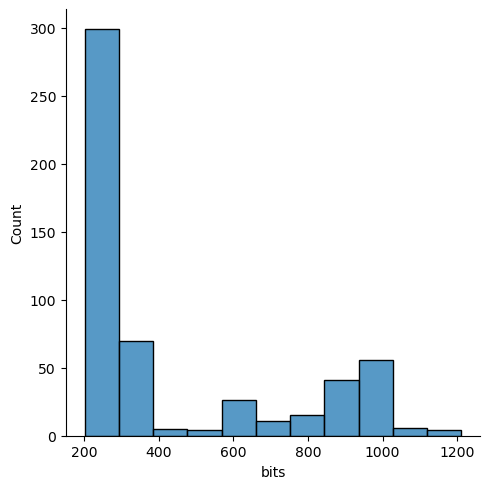

In [19]:
sns.displot(df[(df['bits'] > 200)], x='bits')

In [31]:
# make a FASTA file
bitscore = 200
hits_number = df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].shape[0]
#hits_number = df[(df['bits'] > bitscore)].shape[0]

fasta_file = f"final_metazoa_phylogenies/TMEM140/{hits_number}_TMEM140_chordata_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].sort_values(by='bits', ascending=False).iterrows():
    #for i, row in df[(df['bits'] > bitscore)].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['tseq']
        f.write(f"{header}\n{seq}\n")

# RNF213

In [3]:
file = "final_metazoa_phylogenies/RNF213/5318_RNF213_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

In [17]:
df[df['bits'] > 2000].shape

(2118, 29)

In [24]:
df[df['bits'] > 1500]['phylum'].value_counts().head(20)

phylum
Chordata         2101
Mollusca          150
Cnidaria          103
Porifera            6
Annelida            5
Echinodermata       2
Hemichordata        2
Name: count, dtype: int64

In [21]:
df[df['bits'] > 2000]['protein_name'].value_counts().head(10)

protein_name
E3 ubiquitin-protein ligase RNF213 isoform X2               143
E3 ubiquitin-protein ligase RNF213 isoform X1               140
E3 ubiquitin-protein ligase RNF213                          128
E3 ubiquitin-protein ligase rnf213-alpha-like               102
E3 ubiquitin-protein ligase RNF213 isoform X3               102
RNF213                                                       95
E3 ubiquitin-protein ligase rnf213-alpha-like isoform X2     91
E3 ubiquitin-protein ligase rnf213-alpha-like isoform X1     89
E3 ubiquitin-protein ligase rnf213-alpha                     67
E3 ubiquitin-protein ligase RNF213 isoform X4                63
Name: count, dtype: int64

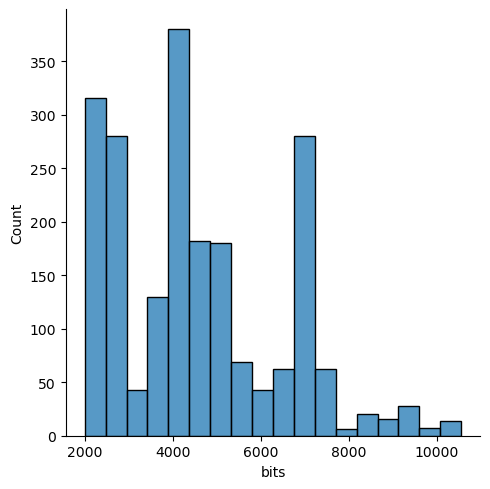

In [11]:
sns.displot(df[(df['bits'] > 2000)], x='bits')

In [ ]:
# make a FASTA file
bitscore = 2000
hits_number = df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].shape[0]
#hits_number = df[(df['bits'] > bitscore)].shape[0]

fasta_file = f"final_metazoa_phylogenies/RNF213/{hits_number}_RNF213_metazoa_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].sort_values(by='bits', ascending=False).iterrows():
    #for i, row in df[(df['bits'] > bitscore)].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# ZNFX1

In [2]:
file = "final_metazoa_phylogenies/ZNFX1/22720_ZNFX1_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

In [20]:
df[df['bits'] > 1100].shape

(1369, 29)

In [21]:
df[df['bits'] > 1100]['phylum'].value_counts().head(10)

phylum
Chordata         1197
Mollusca           62
Cnidaria           49
Arthropoda         29
Echinodermata      24
Annelida            4
Hemichordata        2
Brachiopoda         2
Name: count, dtype: int64

In [22]:
df[df['bits'] > 1100]['protein_name'].value_counts().head(10)

protein_name
NFX1-type zinc finger-containing protein 1                    307
ZNFX1 protein                                                 235
ZNFX1                                                         196
NFX1-type zinc finger-containing protein 1 isoform X2         106
NFX1-type zinc finger-containing protein 1-like               106
NFX1-type zinc finger-containing protein 1 isoform X1          93
unnamed protein product                                        33
PREDICTED: NFX1-type zinc finger-containing protein 1          33
NFX1-type zinc finger-containing protein 1-like isoform X1     31
NFX1-type zinc finger-containing protein 1-like isoform X2     27
Name: count, dtype: int64

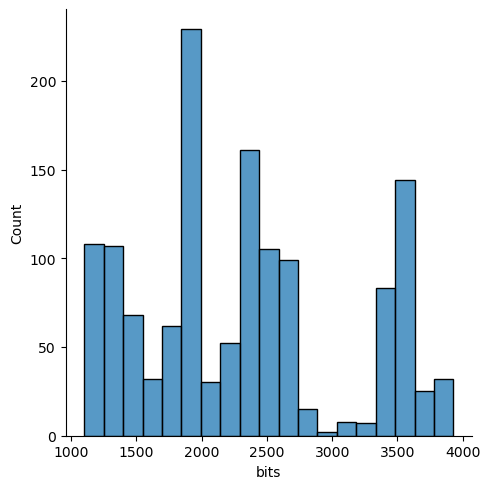

In [19]:
sns.displot(df[(df['bits'] > 1100)], x='bits')

In [23]:
# make a FASTA file
bitscore = 1100
#hits_number = df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].shape[0]
hits_number = df[(df['bits'] > bitscore)].shape[0]

fasta_file = f"final_metazoa_phylogenies/ZNFX1/{hits_number}_ZNFX1_metazoa_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    #for i, row in df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].sort_values(by='bits', ascending=False).iterrows():
    for i, row in df[(df['bits'] > bitscore)].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# TRIM25

In [2]:
file = "final_metazoa_phylogenies/TRIM25/65220_TRIM25_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

In [6]:
df[df['bits'] > 215].shape

(4490, 29)

In [7]:
df[df['bits'] > 215]['phylum'].value_counts().head(10)

phylum
Chordata    4490
Name: count, dtype: int64

In [11]:
df[df['bits'] > 0]['protein_name'].value_counts().head(10)

protein_name
tripartite motif-containing protein 16-like               6034
E3 ubiquitin/ISG15 ligase TRIM25-like                     2928
unnamed protein product                                   1775
E3 ubiquitin-protein ligase TRIM39-like                   1550
NLR family CARD domain-containing protein 3-like          1426
E3 ubiquitin-protein ligase TRIM21-like                   1023
tripartite motif-containing protein 16-like isoform X1     967
E3 ubiquitin/ISG15 ligase TRIM25                           949
NACHT, LRR and PYD domains-containing protein 3-like       828
tripartite motif-containing protein 16-like isoform X2     792
Name: count, dtype: int64

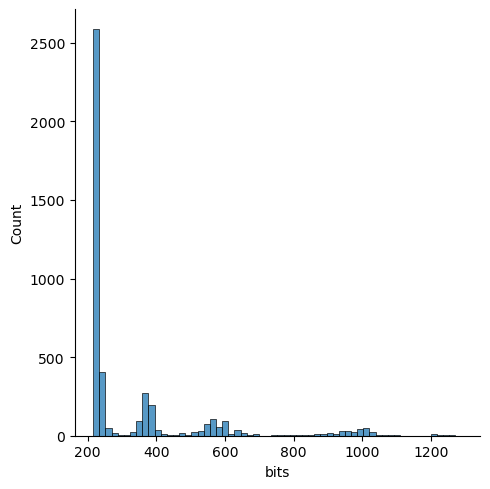

In [9]:
sns.displot(df[(df['bits'] > 215)], x='bits')

In [10]:
# make a FASTA file
bitscore = 215
hits_number = df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].shape[0]
#hits_number = df[(df['bits'] > bitscore)].shape[0]

fasta_file = f"final_metazoa_phylogenies/TRIM25/{hits_number}_TRIM25_chordata_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].sort_values(by='bits', ascending=False).iterrows():
    #for i, row in df[(df['bits'] > bitscore)].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# SCARB2

In [10]:
file = "final_metazoa_phylogenies/SCARB2/13888_SCARB2_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

In [29]:
df[df['bits'] > 300].shape

(1953, 29)

In [30]:
df[df['bits'] > 300]['protein_name'].value_counts().head(10)

protein_name
SCRB2 protein                                  248
lysosome membrane protein 2                    159
lysosome membrane protein 2 isoform X2         134
lysosome membrane protein 2 isoform X1         130
lysosome membrane protein 2-like               119
SCARB2                                         118
lysosome membrane protein 2-like isoform X1    114
lysosome membrane protein 2-like isoform X2    108
lysosome membrane protein 2c                    85
lysosome membrane protein 2a isoform X2         71
Name: count, dtype: int64

In [27]:
df[df['bits'] > 300]['phylum'].value_counts().head(10)

phylum
Chordata         1853
Mollusca           58
Arthropoda         17
Echinodermata      13
Hemichordata        2
Brachiopoda         2
Annelida            2
Cnidaria            2
Placozoa            2
Priapulida          1
Name: count, dtype: int64

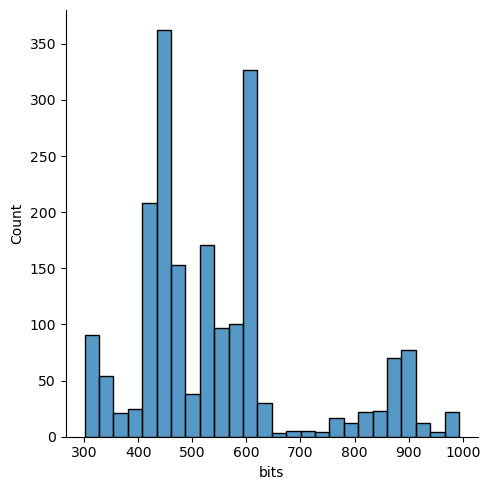

In [28]:
sns.displot(df[(df['bits'] > 300)], x='bits')

In [31]:
# make a FASTA file
bitscore = 300
#hits_number = df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].shape[0]
hits_number = df[(df['bits'] > bitscore)].shape[0]

fasta_file = f"final_metazoa_phylogenies/SCARB2/{hits_number}_SCARB2_metazoa_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    #for i, row in df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].sort_values(by='bits', ascending=False).iterrows():
    for i, row in df[(df['bits'] > bitscore)].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# RTP4

In [3]:
file = "final_metazoa_phylogenies/RTP4/2308_RTP4_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

In [5]:
df[df['bits'] > 0].shape

(2300, 29)

In [6]:
df[df['bits'] > 0]['protein_name'].value_counts().head(10)

protein_name
receptor-transporting protein 3-like    334
receptor-transporting protein 3         164
unnamed protein product                 153
receptor-transporting protein 2         146
receptor-transporting protein 4         115
receptor-transporting protein 1         102
receptor-transporting protein 5          80
receptor-transporting protein 2-like     69
RTP4                                     57
receptor-transporting protein 4-like     56
Name: count, dtype: int64

In [8]:
df[df['bits'] > 75]['phylum'].value_counts().head(10)

phylum
Chordata    1786
Rotifera       6
Cnidaria       1
Name: count, dtype: int64

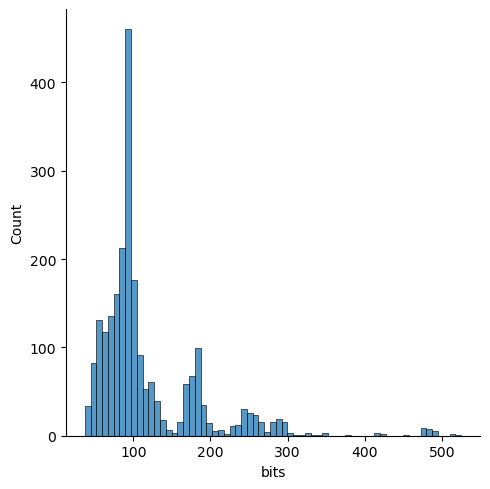

In [4]:
sns.displot(df[(df['bits'] > 0)], x='bits')

In [9]:
# make a FASTA file
bitscore = 0
hits_number = df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].shape[0]
#hits_number = df[(df['bits'] > bitscore)].shape[0]

fasta_file = f"final_metazoa_phylogenies/RTP4/{hits_number}_RTP4_chordata_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].sort_values(by='bits', ascending=False).iterrows():
    #for i, row in df[(df['bits'] > bitscore)].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# RNF19B

In [19]:
file = "final_metazoa_phylogenies/RNF19B/24369_RNF19B_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

In [33]:
df[df['bits'] > 500].shape

(2748, 29)

In [34]:
df[df['bits'] > 500]['protein_name'].value_counts().head(10)

protein_name
E3 ubiquitin-protein ligase RNF19A               275
RN19A ligase                                     240
E3 ubiquitin-protein ligase RNF19B               226
RN19B ligase                                     200
RNF19A                                           182
RNF19B                                           179
E3 ubiquitin-protein ligase RNF19A-like          172
E3 ubiquitin-protein ligase RNF19B isoform X2    150
E3 ubiquitin-protein ligase RNF19B isoform X1    146
E3 ubiquitin-protein ligase RNF19B isoform X3     97
Name: count, dtype: int64

In [32]:
df[df['bits'] > 500]['phylum'].value_counts().head(10)

phylum
Chordata         2488
Arthropoda        190
Mollusca           40
Cnidaria           17
Echinodermata       8
Annelida            3
Brachiopoda         1
Hemichordata        1
Name: count, dtype: int64

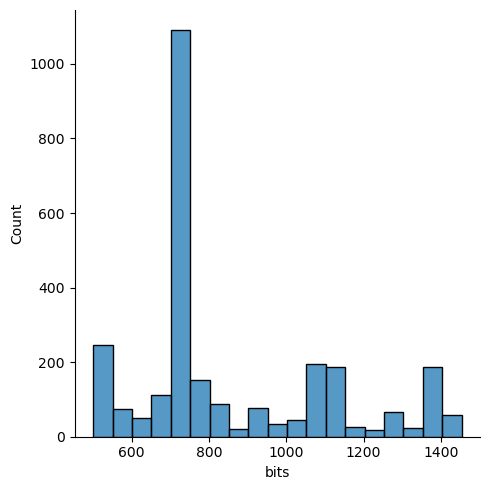

In [35]:
sns.displot(df[(df['bits'] > 500)], x='bits')

In [37]:
# make a FASTA file
bitscore = 500
#hits_number = df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].shape[0]
hits_number = df[(df['bits'] > bitscore)].shape[0]

fasta_file = f"final_metazoa_phylogenies/RNF19B/{hits_number}_RNF19B_metazoa_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    #for i, row in df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].sort_values(by='bits', ascending=False).iterrows():
    for i, row in df[(df['bits'] > bitscore)].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# PLAC8

In [3]:
file = "final_metazoa_phylogenies/PLAC8/5907_PLAC8_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

In [17]:
df[df['bits'] > 80].shape

(2431, 29)

In [16]:
df[df['bits'] > 80]['phylum'].value_counts().head(10)

phylum
Chordata           2281
Mollusca             79
Cnidaria             29
Platyhelminthes      14
Echinodermata        10
Brachiopoda           7
Annelida              7
Bryozoa               3
Hemichordata          1
Name: count, dtype: int64

In [15]:
df[df['bits'] > 80]['protein_name'].value_counts().head(10)

protein_name
PLAC8 protein                                       447
placenta-specific gene 8 protein-like               297
placenta-specific gene 8 protein                    147
cornifelin homolog                                  142
CNFN                                                 99
PLAC8                                                99
placenta-specific gene 8 protein-like isoform X2     65
placenta-specific gene 8 protein-like isoform X1     65
cornifelin                                           55
PREDICTED: placenta-specific gene 8 protein-like     55
Name: count, dtype: int64

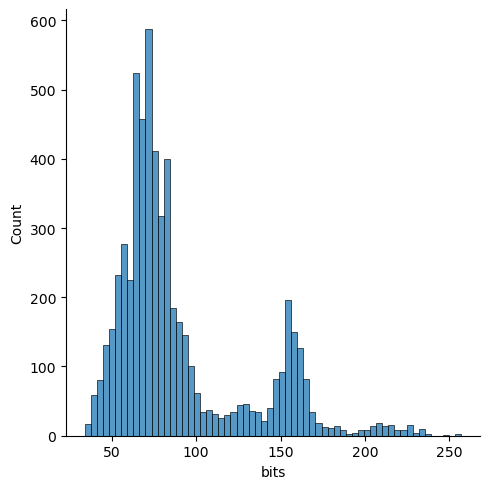

In [5]:
sns.displot(df[(df['bits'] > 0)], x='bits')

In [18]:
# make a FASTA file
bitscore = 80
#hits_number = df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].shape[0]
hits_number = df[(df['bits'] > bitscore)].shape[0]

fasta_file = f"final_metazoa_phylogenies/PLAC8/{hits_number}_PLAC8_metazoa_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    #for i, row in df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].sort_values(by='bits', ascending=False).iterrows():
    for i, row in df[(df['bits'] > bitscore)].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# PLSCR1, PLSCR2

In [18]:
file = "final_metazoa_phylogenies/PLSCR1_PLSCR2/8089_PLSCR1_PLSCR2_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

In [24]:
df[df['bits'] > 300].shape

(3359, 29)

In [26]:
df[df['bits'] > 200]['phylum'].value_counts().head(10)

phylum
Chordata           4025
Arthropoda         1028
Mollusca            189
Echinodermata        82
Platyhelminthes      57
Cnidaria             51
Nematoda             31
Brachiopoda           9
Tardigrada            9
Placozoa              8
Name: count, dtype: int64

In [20]:
df[df['bits'] > 300]['class'].value_counts().head(10)

class
Mammalia          901
Actinopteri       836
Aves              620
Insecta           449
Lepidosauria      166
Amphibia           66
Arachnida          40
Anthozoa           38
Chondrichthyes     34
Bivalvia           32
Name: count, dtype: int64

In [21]:
df[df['bits'] > 300]['protein_name'].value_counts().head(10)

protein_name
phospholipid scramblase 2-like             180
phospholipid scramblase 1 isoform X2       178
phospholipid scramblase 1-like             170
phospholipid scramblase 1                  155
phospholipid scramblase 1 isoform X1       144
PLS1 scramblase                            135
phospholipid scramblase 2 isoform X1       121
phospholipid scramblase family member 5    117
PLS5 scramblase                            108
PLS2 scramblase                             99
Name: count, dtype: int64

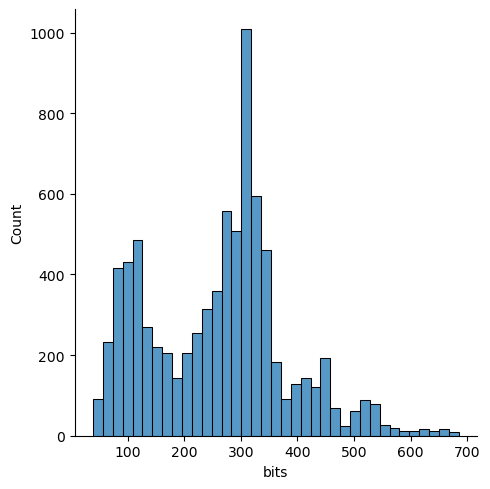

In [3]:
sns.displot(df[(df['bits'] > 0)], x='bits')

In [27]:
# make a FASTA file
bitscore = 200
hits_number = df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].shape[0]
#hits_number = df[(df['bits'] > bitscore)].shape[0]

fasta_file = f"final_metazoa_phylogenies/PLSCR1_PLSCR2/{hits_number}_PLSCR1_PLSCR2_metazoa_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].sort_values(by='bits', ascending=False).iterrows():
    #for i, row in df[(df['bits'] > bitscore)].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# MX1/MX2

In [42]:
file = "final_metazoa_phylogenies/MX1_MX2/24182_MX1_MX2_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

In [35]:
df[df['bits'] > 250].shape

(2694, 28)

In [36]:
df[df['bits'] > 250]['protein_name'].value_counts().head(10)

protein_name
MX protein                                                   242
interferon-induced GTP-binding protein Mx-like               215
interferon-induced GTP-binding protein Mx1                   133
MX1                                                           97
interferon-induced GTP-binding protein Mx2-like               89
interferon-induced GTP-binding protein Mx2                    88
interferon-induced GTP-binding protein Mx1-like               84
interferon-induced GTP-binding protein Mx3-like               77
interferon-induced GTP-binding protein Mx                     71
interferon-induced GTP-binding protein Mx-like isoform X2     67
Name: count, dtype: int64

In [43]:
df[df['bits'] > 300]['phylum'].value_counts().head(10)

phylum
Chordata           2574
Mollusca             14
Platyhelminthes      10
Annelida              4
Hemichordata          2
Name: count, dtype: int64

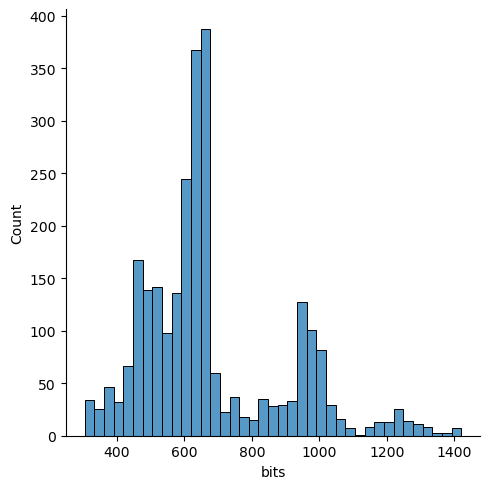

In [41]:
sns.displot(df[(df['bits'] > 300)], x='bits')

In [44]:
# make a FASTA file
bitscore = 300
hits_number = df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].shape[0]

fasta_file = f"final_metazoa_phylogenies/MX1_MX2/{hits_number}_MX1_MX2_chordata_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# IFI6

In [2]:
file = "final_metazoa_phylogenies/IFI6/2347_IFI6_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

In [19]:
df[df['bits'] > 60].shape

(937, 29)

In [20]:
df[df['bits'] > 60]['protein_name'].value_counts().head(10)

protein_name
interferon alpha-inducible protein 27-like protein 2                104
interferon alpha-inducible protein 27-like protein 2A                60
interferon alpha-inducible protein 6                                 56
IFI6                                                                 50
interferon alpha-inducible protein 27-like protein 2 isoform X2      47
interferon alpha-inducible protein 27-like protein 2 isoform X1      36
interferon alpha-inducible protein 6 isoform X2                      31
interferon alpha-inducible protein 6 isoform X1                      29
interferon alpha-inducible protein 27-like protein 2A isoform X1     25
interferon alpha-inducible protein 27, mitochondrial-like            21
Name: count, dtype: int64

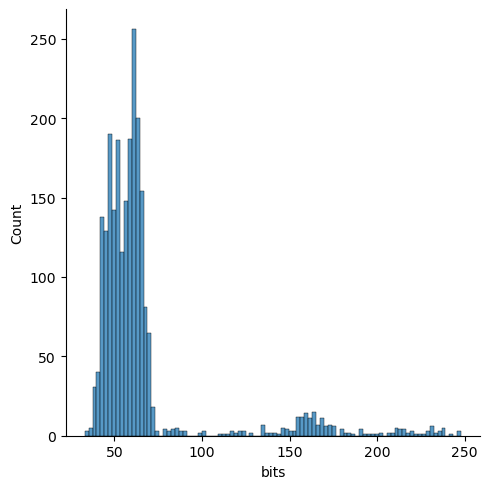

In [14]:
sns.displot(df[(df['bits'] > 0)], x='bits')

In [23]:
# make a FASTA file
bitscore = 60
hits_number = df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].shape[0]

fasta_file = f"final_metazoa_phylogenies/IFI6/{hits_number}_IFI6_metazoa_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# DRAM1

In [12]:
file = "final_metazoa_phylogenies/DRAM1/7265_DRAM1_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

In [19]:
df[df['bits'] > 100].shape

(3182, 29)

In [20]:
df[df['bits'] > 100]['protein_name'].value_counts().head(10)

protein_name
DNA damage-regulated autophagy modulator protein 1               352
DRAM1 protein                                                    243
DRAM2 protein                                                    236
DNA damage-regulated autophagy modulator protein 2               211
DRAM1                                                            176
DNA damage-regulated autophagy modulator protein 2 isoform X2    133
DNA damage-regulated autophagy modulator protein 2 isoform X1    119
DNA damage-regulated autophagy modulator protein 2-like          118
DRAM2                                                            118
DNA damage-regulated autophagy modulator protein 1 isoform X1    110
Name: count, dtype: int64

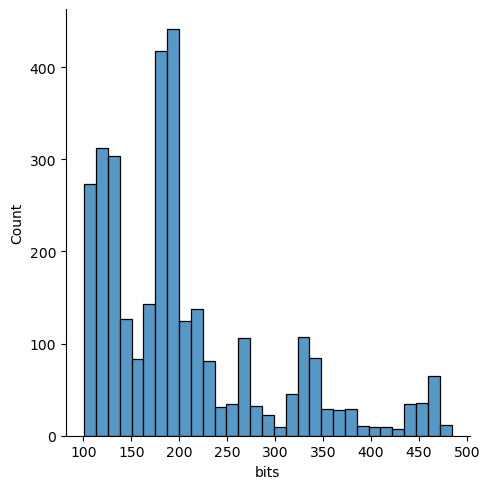

In [18]:
sns.displot(df[(df['bits'] > 100)], x='bits')

In [21]:
# make a FASTA file
bitscore = 100
hits_number = df[(df['bits'] > bitscore) & (df['kingdom'] == 'Metazoa')].shape[0]

fasta_file = f"final_metazoa_phylogenies/DRAM1/{hits_number}_DRAM1_metazoa_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[(df['bits'] > bitscore) & (df['kingdom'] == 'Metazoa')].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# TTC39B

In [2]:
file = "final_metazoa_phylogenies/TTC39B/7643_TTC39B_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

In [7]:
df[df['bits'] > 500].shape

(4052, 29)

In [8]:
df[df['phylum'] == 'Chordata'].shape

(5963, 29)

In [6]:
df[df['bits'] > 500]['protein_name'].value_counts().head(10)

protein_name
tetratricopeptide repeat protein 39A isoform X1    374
tetratricopeptide repeat protein 39A isoform X2    347
tetratricopeptide repeat protein 39B isoform X2    240
tetratricopeptide repeat protein 39B isoform X1    228
TTC39B                                             215
TT39A protein                                      210
TT39B protein                                      200
tetratricopeptide repeat protein 39A isoform X3    188
TTC39A                                             167
tetratricopeptide repeat protein 39B-like          141
Name: count, dtype: int64

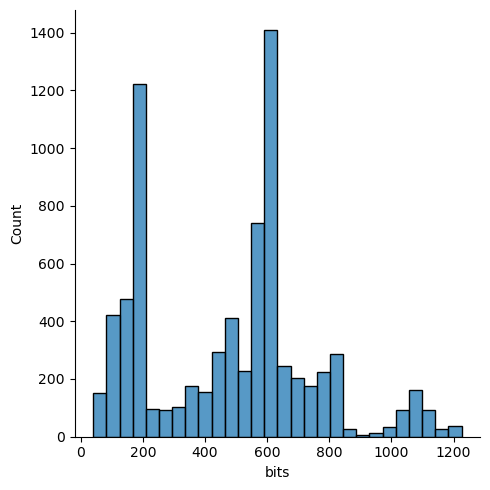

In [5]:
sns.displot(df[(df['bits'] > 0)], x='bits')

In [10]:
# make a FASTA file
bitscore = 500
hits_number = df[(df['bits'] > bitscore) & (df['kingdom'] == 'Metazoa')].shape[0]

fasta_file = f"final_metazoa_phylogenies/TTC39B/{hits_number}_TTC39B_metazoa_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[(df['bits'] > bitscore) & (df['kingdom'] == 'Metazoa')].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# BTN3A1, BTN3A3

In [3]:
file = "final_metazoa_phylogenies/BT3A1_BTN3A3/56863_BT3A1_BTN3A3_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

In [23]:
df[df['bits'] > 400].shape

(1005, 29)

In [17]:
df[df['bits'] > 400]['protein_name'].value_counts().head(10)

protein_name
butyrophilin subfamily 1 member A1               90
BTN1A1                                           62
butyrophilin subfamily 1 member A1-like          38
BTN2A2                                           30
butyrophilin subfamily 3 member A3-like          29
butyrophilin subfamily 2 member A2-like          27
butyrophilin subfamily 3 member A3 isoform X2    25
butyrophilin subfamily 1 member A1 isoform X1    25
butyrophilin subfamily 1 member A1 isoform X2    21
butyrophilin subfamily 3 member A3 isoform X1    21
Name: count, dtype: int64

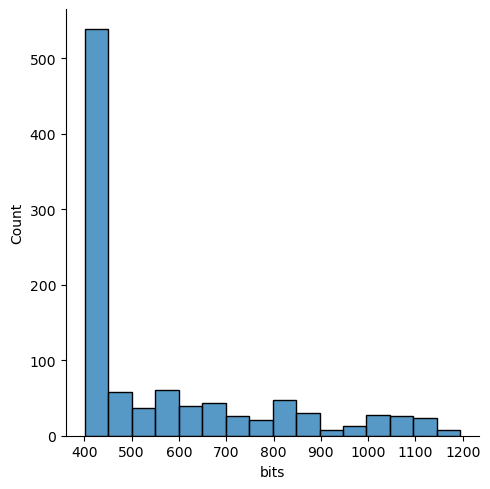

In [22]:
sns.displot(df[(df['bits'] > 400)], x='bits')

In [24]:
# make a FASTA file
bitscore = 400
hits_number = df[(df['bits'] > bitscore) & (df['kingdom'] == 'Metazoa')].shape[0]

fasta_file = f"final_metazoa_phylogenies/BT3A1_BTN3A3/{hits_number}_BT3A1_BTN3A3_metazoa_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[(df['bits'] > bitscore) & (df['kingdom'] == 'Metazoa')].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# BST2

In [ ]:
import pandas as pd
import re

In [38]:
file = "extended_nr_phylogenies/BST2/469_BST2_ensembl_nr_hits_processed.tsv"
df = pd.read_csv(file, sep='\t')

# remove duplicated records (sometimes present in gene family records: OAS1_OAS2_OAS3)
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target')

# removes partial and low quality records
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

# remove records with umbigious characters
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

# make a gene column
df['gene'] = df['query'].apply(lambda x: x.split('-')[-1])

In [45]:
def normalize_protein_name(name):
    if pd.isna(name):
        return name

    name = re.sub(r'isoform\s*\S*', '', name, flags=re.IGNORECASE)
    name = name.lower()
    name = re.sub(r'\s+', ' ', name).strip()

    return name


def select_records(df, verbose=True):
    df = df.copy()

    df['base_name'] = df['protein_name'].apply(normalize_protein_name)
    df['source'] = df['source'].str.lower()

    selected_groups = []

    for species, group in df.groupby('species'):

        ensembl = group[group['source'] == 'ensembl']
        nr = group[group['source'] == 'nr']

        # --- Ensembl priority ---
        if not ensembl.empty:

            for base_name, ens_subgrp in ensembl.groupby('base_name'):

                best_idx = ens_subgrp['bits'].idxmax()
                best_row = ens_subgrp.loc[best_idx]

                # --- Print Ensembl internal competition ---
                if verbose and len(ens_subgrp) > 1:
                    print(f"\n[Ensembl | {species}]")
                    print(f"Base name: '{base_name}'")
                    print(f"SELECTED: {best_row['protein_name']} (bits={best_row['bits']})")

                    losers = ens_subgrp.drop(best_idx)
                    for _, row in losers.iterrows():
                        print(f"REMOVED:  {row['protein_name']} (bits={row['bits']}) → lower Ensembl bitscore")

                # --- Compare against NR ---
                nr_matches = nr[nr['base_name'] == base_name]

                if verbose and not nr_matches.empty:
                    print(f"\n[NR removed due to Ensembl | {species}]")
                    print(f"Base name: '{base_name}'")
                    print(f"ENSEMBL SELECTED: {best_row['protein_name']} (bits={best_row['bits']})")

                    for _, row in nr_matches.iterrows():
                        print(
                            f"REMOVED NR: {row['protein_name']} (bits={row['bits']}) "
                            f"{row.get('target','')} → replaced by Ensembl"
                        )

                selected_groups.append(ens_subgrp.loc[[best_idx]])

            continue

        # --- NR fallback ---
        if nr.empty:
            continue

        for base_name, subgrp in nr.groupby('base_name'):

            if len(subgrp) > 1:
                best_idx = subgrp['bits'].idxmax()
                best_row = subgrp.loc[best_idx]

                if verbose:
                    print(f"\n[NR | {species}]")
                    print(f"Base name: '{base_name}'")
                    print(f"SELECTED: {best_row['protein_name']} (bits={best_row['bits']}) {best_row.get('target','')}")

                    losers = subgrp.drop(best_idx)
                    for _, row in losers.iterrows():
                        print(
                            f"REMOVED:  {row['protein_name']} (bits={row['bits']}) "
                            f"{row.get('target','')} → lower bitscore"
                        )

            idx = subgrp['bits'].idxmax()
            selected_groups.append(subgrp.loc[[idx]])

    result = pd.concat(selected_groups).reset_index(drop=True)

    return result

In [53]:
df = select_records(df)


[NR | Aotus vociferans]
Base name: 'tetherin'
SELECTED: tetherin (bits=196) ACN12812.1
REMOVED:  tetherin (bits=196) ACN12813.1 → lower bitscore

[NR | Bubalus bubalis]
Base name: 'bone marrow stromal antigen 2'
SELECTED: bone marrow stromal antigen 2 (bits=104) XP_006057961.2
REMOVED:  bone marrow stromal antigen 2 isoform X1 (bits=71) XP_025149583.2 → lower bitscore
REMOVED:  bone marrow stromal antigen 2 isoform X2 (bits=62) XP_045022700.1 → lower bitscore

[NR | Bubalus bubalis]
Base name: 'bone marrow stromal antigen 2-like'
SELECTED: bone marrow stromal antigen 2-like isoform X1 (bits=84) XP_045022701.1
REMOVED:  bone marrow stromal antigen 2-like isoform X2 (bits=64) XP_045022702.1 → lower bitscore

[NR | Bubalus carabanensis]
Base name: 'bone marrow stromal antigen 2-like'
SELECTED: bone marrow stromal antigen 2-like (bits=103) XP_055422467.1
REMOVED:  bone marrow stromal antigen 2-like (bits=86) XP_055422465.1 → lower bitscore

[NR | Callorhinus ursinus]
Base name: 'bone marr

In [ ]:
df.shape

(240, 29)

In [54]:
df[df['bits'] > 0]['protein_name'].value_counts().head(10)

protein_name
bone marrow stromal antigen 2                    79
BST2                                             37
BST-2                                            24
bone marrow stromal cell antigen 2               15
PREDICTED: bone marrow stromal antigen 2         10
bone marrow stromal antigen 2 isoform X2          9
bone marrow stromal antigen 2 isoform X1          8
bone marrow stromal antigen 2-like                8
tetherin                                          6
bone marrow stromal antigen 2-like isoform X1     3
Name: count, dtype: int64

In [55]:
df[df['bits'] > 0]['domain'].value_counts().head(10)

domain
Eukaryota    238
Bacteria       1
Name: count, dtype: int64

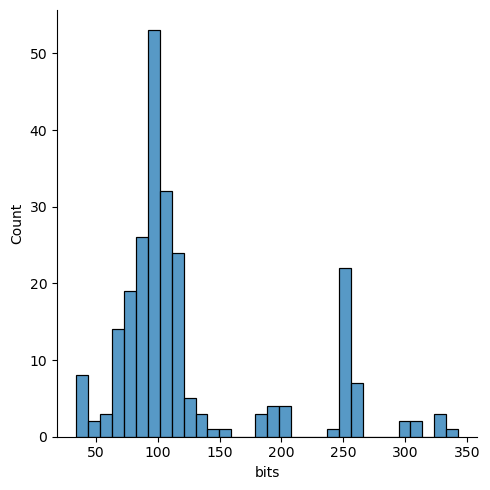

In [56]:
sns.displot(df[(df['bits'] > 0)], x='bits')

In [57]:
# make a FASTA file
bitscore = 0
hits_number = df[(df['bits'] > bitscore)].shape[0]

fasta_file = f"final_metazoa_phylogenies/BST2/{hits_number}_BST2_all_domains_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[(df['bits'] > bitscore)].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# OAS1, OAS2, OAS3

In [3]:
file = "final_metazoa_phylogenies/OAS1_OAS2_OAS3/3217_OAS1_OAS2_OAS3_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

In [9]:
df[(df['species'] == 'Homo sapiens') & (df['protein_name'] == 'OASL')].iloc[:,:].sort_values(by='bits', ascending=True)

,index,query,target,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,...,kingdom,phylum,class,order,family,genus,species,protein_name,protein_sequence,gene
2065,8370,ENSP00000228928.7-OAS3,ENSP00000257570.4,0.408,345,201,0,747,1086,0.313,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Homo,Homo sapiens,OASL,MALMQELYSTPASRLDSFVAQWLQPHREWKEEVLDAVRTVEEFLRQ...,OAS3


In [4]:
df[(df['kingdom'] == 'Metazoa') & (df['bits'] > 100)].shape

(2858, 29)

In [5]:
df[(df['phylum'] == 'Chordata') & (df['bits'] > 100)].shape

(2675, 29)

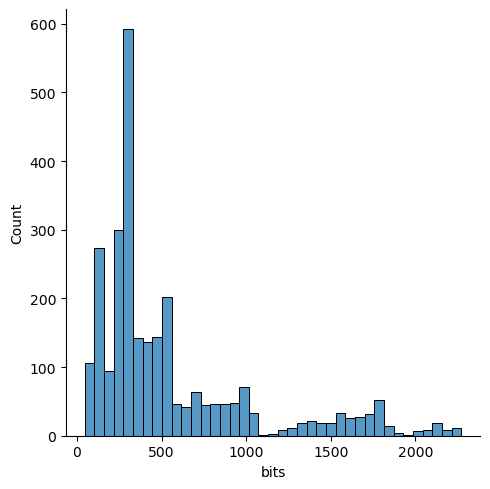

In [19]:
sns.displot(df[(df['phylum'] == 'Chordata') & (df['bits'] > 0)], x='bits')

In [7]:
# make a FASTA file
bitscore = 100
hits_number = df[(df['bits'] > bitscore) & (df['kingdom'] == 'Metazoa')].shape[0]

fasta_file = f"final_metazoa_phylogenies/OAS1_OAS2_OAS3/{hits_number}_OAS1_OAS2_OAS3_metazoa_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[(df['bits'] > bitscore) & (df['kingdom'] == 'Metazoa')].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# RSAD2

In [3]:
file = "final_metazoa_phylogenies/RSAD2/1395_RSAD2_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target')

key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)  # creates 'partial|low quality'
df = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df = df[df['protein_sequence'].str.fullmatch(pattern, na=False)]

df['gene'] = df['query'].apply(lambda x: x.split('-')[-1])

In [6]:
df[df['bits'] > 100].shape

(1286, 28)

In [7]:
df[df['bits'] > 100].shape

(1286, 28)

In [8]:
df[df['bits'] > 100]['phylum'].value_counts().head(10)

phylum
Chordata           1078
Arthropoda           89
Mollusca             51
Rotifera             32
Cnidaria             20
Porifera              6
Echinodermata         5
Brachiopoda           2
Platyhelminthes       2
Annelida              1
Name: count, dtype: int64

In [9]:
df[(df['bits'] > 100)]['protein_name'].value_counts().head(10)

protein_name
radical S-adenosyl methionine domain-containing protein 2               267
RSAD2 protein                                                           247
RSAD2                                                                   190
unnamed protein product                                                  75
radical S-adenosyl methionine domain-containing protein 2-like           60
S-adenosylmethionine-dependent nucleotide dehydratase RSAD2              55
PREDICTED: radical S-adenosyl methionine domain-containing protein 2     46
Radical S-adenosyl methionine domain-containing protein 2                36
radical S-adenosyl methionine domain-containing protein 2 isoform X2     34
radical S-adenosyl methionine domain-containing protein 2 isoform X1     30
Name: count, dtype: int64

In [36]:
df[df['bits'] > 100]['protein_name'].value_counts().head(10)

protein_name
viperin family antiviral radical SAM protein                      612
radical S-adenosyl methionine domain-containing protein 2         292
RSAD2 protein                                                     247
RSAD2                                                             190
radical SAM protein                                               183
radical SAM enzyme                                                 94
unnamed protein product                                            93
Radical S-adenosyl methionine domain-containing protein 2          93
radical S-adenosyl methionine domain-containing protein 2-like     61
S-adenosylmethionine-dependent nucleotide dehydratase RSAD2        55
Name: count, dtype: int64

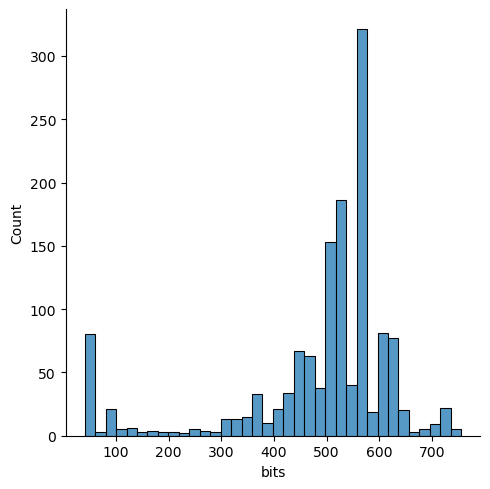

In [4]:
sns.displot(df[df['bits'] > 0], x='bits')

In [10]:
# make a FASTA file
bitscore = 100
hits_number = df[df['bits'] > bitscore].shape[0]

fasta_file = f"final_metazoa_phylogenies/RSAD2/{hits_number}_RSAD2_metazoa_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[df['bits'] > bitscore].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

In [45]:
# make an annotatin file
hits_number = df.drop_duplicates(subset='target').shape[0]

tsv_file = f"final_metazoa_phylogenies/RSAD2/{hits_number}_RSAD2_all_domains.tsv"
annotation_file = f"final_metazoa_phylogenies/RSAD2/{hits_number}_RSAD2_all_domains_annotation.tsv"

df.to_csv(tsv_file, index=False, sep='\t')

df[[
    'target', 'gene', 'source',
    'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species',
    'protein_name', 'fident', 'qcov', 'qlen', 'tcov', 'tlen', 'bits', 'evalue']].to_csv(annotation_file, index=False, sep='\t')


# IFITM1/IFITM2/IFITM3

In [2]:
file = "final_metazoa_phylogenies/IFITM1_IFITM2_IFITM3/3929_IFITM1_IFITM2_IFITM3_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

In [17]:
df[df['bits'] > 70].shape

(3374, 29)

In [15]:
df[df['bits'] > 70]['protein_name'].value_counts().head(10)

protein_name
dispanin subfamily A member 2b-like                371
interferon-induced transmembrane protein 3-like    295
interferon-induced transmembrane protein 1-like    240
IFM5 protein                                       204
IFITM5                                             145
interferon-induced transmembrane protein 5         144
interferon-induced transmembrane protein 10        132
IFM1 protein                                       106
interferon-induced transmembrane protein 5-like     95
interferon-induced transmembrane protein 3          85
Name: count, dtype: int64

In [27]:
df[df['bits'] > 100]['class'].value_counts().head(10)

class
Mammalia        1087
Lepidosauria      30
Actinopteri        8
Aves               8
Amphibia           7
Cladistia          2
Name: count, dtype: int64

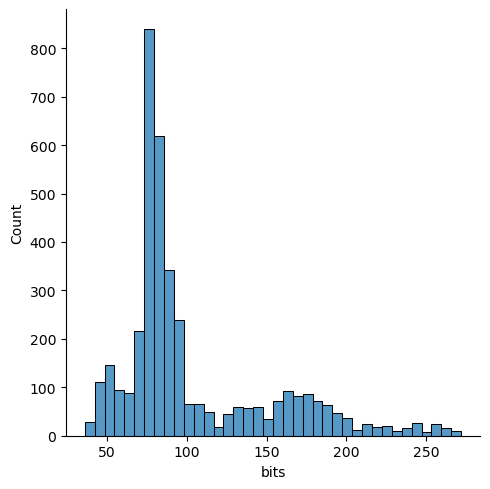

In [4]:
sns.displot(df[df['bits'] > 0], x='bits')

In [12]:
# make a FASTA file
bitscore = 80
hits_number = df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].shape[0]

fasta_file = f"final_metazoa_phylogenies/IFITM1_IFITM2_IFITM3/{hits_number}_IFITM1_IFITM2_IFITM3_chordata_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[(df['bits'] > bitscore) & (df['phylum'] == 'Chordata')].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

In [8]:
# add other gene members

ifitm5_ifitm10_list = [
    'ENSP00000372059.2',
    'ENSGALP00010029733.1',
    'ENSACAP00000017197.3',
    'ENSXETP00000104382.1',
    'ENSECRP00000002894.1',
    'ENSP00000344430.4',
    'ENSGALP00010036876.1',
    'ENSACAP00000028728.1',
    'ENSXETP00000078597.1',
    'ENSCMIP00000017495.1']

file_family = "provisional_ensembl_phylogenies/ENSG00000300510_IFITM1_IFITM10_IFITM2_IFITM3_IFITM5/ENSG00000300510_IFITM1_IFITM10_IFITM2_IFITM3_IFITM5_ensembl_master_table.csv"
df_family = pd.read_csv(file_family)

In [12]:
df_family.columns

Index(['source_id', 'source_name', 'gene_id', 'gene_name', 'transcript_id',
       'protein_id', 'species', 'position', 'perc_id', 'perc_pos', 'type',
       'method_link_type', 'upstream_seq_1500bp', 'gene_seq',
       'downstream_seq_1500bp', 'cdna_seq', 'cds', 'protein_seq'],
      dtype='object')

In [16]:
for index, row in df_family[df_family['protein_id'].isin(ifitm5_ifitm10_list)].iterrows():
    protein_id = row['protein_id']
    protein_seq = row['protein_seq']
    species = row['species']
    gene_name = row['gene_name']
    #print(f">{protein_id}_{gene_name}_{species}\n{protein_seq}")
    print(f"{protein_id}	ensembl	Eukaryota	Metazoa	Chordata	{species}	{gene_name}")

ENSXETP00000104382.1	ensembl	Eukaryota	Metazoa	Chordata	xenopus_tropicalis	ifitm5
ENSCMIP00000017495.1	ensembl	Eukaryota	Metazoa	Chordata	callorhinchus_milii	nan
ENSGALP00010029733.1	ensembl	Eukaryota	Metazoa	Chordata	gallus_gallus	IFITM5
ENSACAP00000017197.3	ensembl	Eukaryota	Metazoa	Chordata	anolis_carolinensis	IFITM5
ENSECRP00000002894.1	ensembl	Eukaryota	Metazoa	Chordata	erpetoichthys_calabaricus	ifitm5
ENSP00000372059.2	ensembl	Eukaryota	Metazoa	Chordata	homo_sapiens	IFITM5
ENSP00000344430.4	ensembl	Eukaryota	Metazoa	Chordata	homo_sapiens	IFITM10
ENSACAP00000028728.1	ensembl	Eukaryota	Metazoa	Chordata	anolis_carolinensis	IFITM10
ENSXETP00000078597.1	ensembl	Eukaryota	Metazoa	Chordata	xenopus_tropicalis	ifitm10
ENSGALP00010036876.1	ensembl	Eukaryota	Metazoa	Chordata	gallus_gallus	IFITM10


# PARP12/ ZC3HAV1

In [2]:
file = "final_metazoa_phylogenies/PARP12_ZC3HAV1/21136_PARP12_ZC3HAV1_metazoa.tsv"
df = pd.read_csv(file, sep='\t')

In [3]:
df[df['bits'] > 0].drop_duplicates(subset='target').shape

(21136, 28)

In [4]:
df[df['bits'] > 800]['protein_name'].value_counts().head(10)

protein_name
protein mono-ADP-ribosyltransferase PARP12               86
PARP12                                                   75
ZC3HAV1                                                  74
zinc finger CCCH-type antiviral protein 1                69
zinc finger CCCH-type antiviral protein 1 isoform X1     65
zinc finger CCCH-type antiviral protein 1 isoform X2     63
protein mono-ADP-ribosyltransferase PARP12 isoform X2    31
protein mono-ADP-ribosyltransferase PARP12 isoform X1    30
PREDICTED: poly                                          25
zinc finger CCCH-type antiviral protein 1 isoform X3     25
Name: count, dtype: int64

In [7]:
df[df['bits'] > 400]['class'].value_counts().head(10)

class
Aves              1099
Actinopteri        926
Mammalia           837
Lepidosauria       125
Amphibia            50
Chondrichthyes      32
Cladistia           19
Hyperoartia          1
Name: count, dtype: int64

In [9]:
df[df['bits'] > 500].shape

(2140, 28)

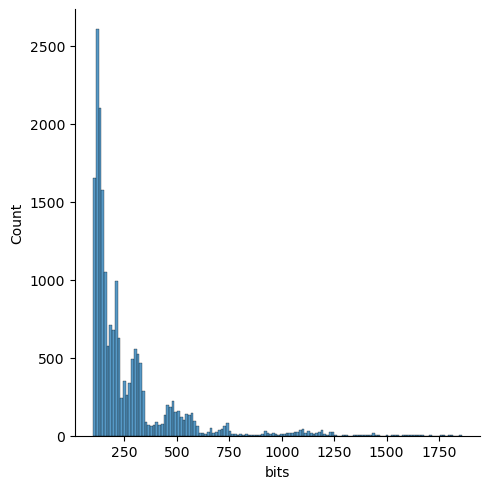

In [10]:
sns.displot(df[df['bits'] > 100], x='bits')

In [11]:
bitscore = 400
hits_number = df[df['bits'] > bitscore].shape[0]

# Write FASTA
fasta_file = f"final_metazoa_phylogenies/PARP12_ZC3HAV1/{hits_number}_PARP12_ZC3HAV1_metazoa_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[df['bits'] > bitscore].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# EHD4

In [2]:
file = "final_metazoa_phylogenies/EHD4/28938_EHD4_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

In [4]:
df[df['bits'] > 800].shape

(1742, 29)

In [8]:
df[df['bits'] > 800]['protein_name'].value_counts().head(10)

protein_name
EH domain-containing protein 4         226
EH domain-containing protein 3         183
EHD4 protein                           174
EHD3                                   152
EHD4                                   150
EH domain-containing protein 1          90
EH domain-containing protein 1a         73
EHD1                                    71
EHD1A                                   60
EH domain-containing protein 1-like     39
Name: count, dtype: int64

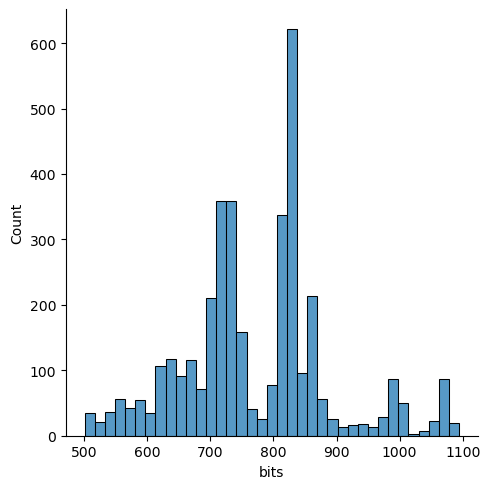

In [9]:
sns.displot(df[df['bits'] > 500], x='bits')

In [10]:
bitscore = 500
hits_number = df[df['bits'] > bitscore].shape[0]

# Write FASTA
fasta_file = f"final_metazoa_phylogenies/EHD4/{hits_number}_EHD4_metazoa_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[df['bits'] > bitscore].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# TRIM5

In [3]:
file = "final_metazoa_phylogenies/TRIM5/34643_TRIM5_metazoa.tsv"
df = pd.read_csv(file, sep='\t')

In [7]:
df[df['bits'] > 300].shape

(2063, 28)

In [11]:
df[df['bits'] > 300]['class'].value_counts()

class
Mammalia    2063
Name: count, dtype: int64

In [8]:
df[df['bits'] > 300]['protein_name'].value_counts()

protein_name
E3 ubiquitin-protein ligase TRIM21                     106
tripartite motif-containing protein 6 isoform X2        72
TRIM6                                                   70
tripartite motif-containing protein 6 isoform X1        66
tripartite motif-containing protein 5-like              53
                                                      ... 
TRIM5/cyclophilin A V3 fusion protein                    1
TRIM5-3 alpha isoform                                    1
tripartite motif-containing protein 5 isoform delta      1
tripartite motif protein TRIM5 isoform delta             1
TRIM5 isoform 5                                          1
Name: count, Length: 344, dtype: int64

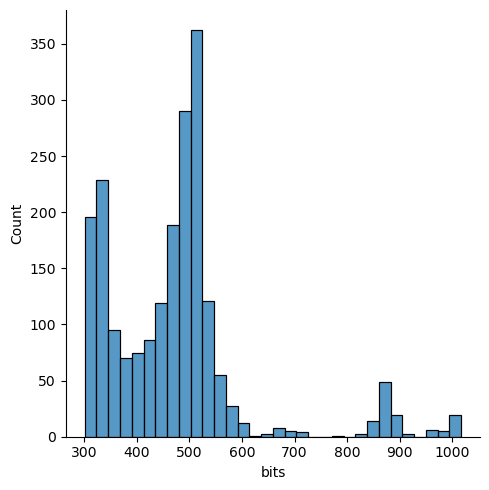

In [9]:
sns.displot(df[df['bits'] > 300], x='bits')

In [12]:
bitscore = 300
hits_number = df[df['bits'] > bitscore].shape[0]

# Write FASTA
fasta_file = f"final_metazoa_phylogenies/TRIM5/{hits_number}_TRIM5_mammalia_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[df['bits'] > bitscore].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# ISG20

In [2]:
file = "final_metazoa_phylogenies/ISG20/13108_ISG20_metazoa.tsv"
df = pd.read_csv(file, sep='\t')
df = df[~((df["species"] == "Homo sapiens") & (df["source"] == "nr"))]
df = df.sort_values(by='bits', ascending=False).drop_duplicates(subset='target').reset_index()

In [3]:
df.shape

(13108, 28)

In [9]:
df[(df['bits'] > 160) & (df["species"] == "Homo sapiens")]

,index,query,target,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,...,kingdom,phylum,class,order,family,genus,species,protein_name,protein_sequence,gene
0,0,ENSP00000306565.5-ISG20,ENSP00000306565.5,1.000,181,0,0,1,181,1.000,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Homo,Homo sapiens,ISG20,MAGSREVVAMDCEMVGLGPHRESGLARCSLVNVHGAVLYDKFIRPE...,ISG20
442,438,ENSP00000306565.5-ISG20,ENSP00000331944.3,0.582,158,65,0,8,164,0.867,...,Metazoa,Chordata,Mammalia,Primates,Hominidae,Homo,Homo sapiens,AEN,MVPREAPESAQCLCPSLTIPNAKDVLRKRHKRRSRQHQRFMARKAL...,ISG20


In [63]:
df[df['bits'] > 160].shape

(629, 28)

In [65]:
df[df['bits'] > 160]['protein_name'].value_counts()

protein_name
ISG20                                                   79
apoptosis-enhancing nuclease                            78
interferon-stimulated gene 20 kDa protein               76
interferon-stimulated gene 20 kDa protein isoform X2    46
interferon-stimulated gene 20 kDa protein isoform X1    43
                                                        ..
hypothetical protein KIL84_005801                        1
hypothetical protein INR49_017563                        1
interferon-stimulated exonuclease-like 2                 1
hypothetical protein FD755_019222                        1
PREDICTED: apoptosis-enhancing nuclease isoform X1       1
Name: count, Length: 80, dtype: int64

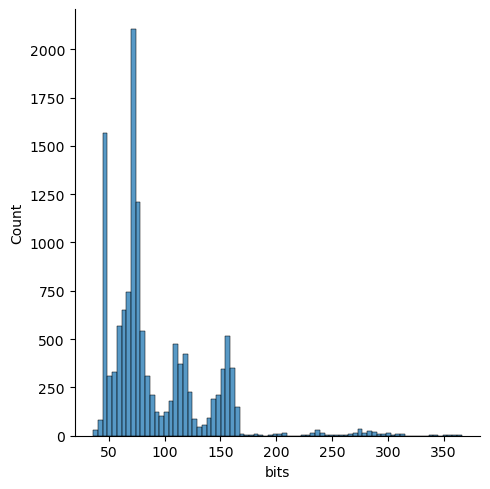

In [3]:
sns.displot(df[df['bits'] > 0], x='bits')

In [12]:
bitscore = 100
hits_number = df[df['bits'] > bitscore].shape[0]

# Write FASTA
fasta_file = f"final_metazoa_phylogenies/ISG20/{hits_number}_ISG20_metazoa_{bitscore}_bitscore_filtered.fasta"

with open(fasta_file, "w") as f:
    for i, row in df[df['bits'] > bitscore].sort_values(by='bits', ascending=False).iterrows():
        header = f">{row['target']}"
        seq = row['protein_sequence']
        f.write(f"{header}\n{seq}\n")

# Make TSVs and FASTAs for each set of genes

In [2]:
file = "extended_nr_phylogenies/all_ensembl_nr_hits_extended.tsv"
df = pd.read_csv(file, sep='\t')

In [ ]:
word_counts = (
    df['protein_name']
    .str.lower()                      # normalize case
    .str.cat(sep=' ')                 # concatenate all rows
    .split()                          # split into words
)

from collections import Counter
word_counts = Counter(word_counts)

# Top 20 most common words
print(word_counts.most_common(100))

In [25]:
key_words = ['partial', 'low quality']
pattern = '|'.join(key_words)  # creates 'partial|low quality'
df_clean = df[~df['protein_name'].str.contains(pattern, case=False, na=False)]

In [26]:
VALID_AA = set("ARNDCEQGHILKMFPSTWYVX")
pattern = f"^[{''.join(VALID_AA)}]+$"
df_clean = df_clean[df_clean['protein_sequence'].str.fullmatch(pattern, na=False)]

In [33]:
df_clean['gene'] = df_clean['query'].apply(lambda x: x.split('-')[-1])

In [40]:
df_clean.to_csv("final_metazoa_phylogenies/all_clean_mmseqs_ensembl_nr_hits_combined.tsv", sep='\t', index=False)

In [38]:
import os
import pandas as pd

# Paths
input_dir = "extended_nr_phylogenies"
output_dir = "final_metazoa_phylogenies"

os.makedirs(output_dir, exist_ok=True)

# Optional: ensure sequences are uppercase
df_clean['protein_sequence'] = df_clean['protein_sequence'].str.upper()

for folder in os.listdir(input_dir):
    folder_path = os.path.join(input_dir, folder)

    if not os.path.isdir(folder_path):
        continue

    # Example: "OAS1_OAS2_OAS3" → ["OAS1", "OAS2", "OAS3"]
    genes = folder.split("_")
    
    # Create corresponding output folder
    out_folder = os.path.join(output_dir, folder)
    os.makedirs(out_folder, exist_ok=True)
    
    # Filter dataframe
    df_subset_metazoa = df_clean[df_clean['gene'].isin(genes) & (df_clean['kingdom'] == 'Metazoa')].copy()
    
    if df_subset_metazoa.empty:
        print(f"⚠️ No data found for {folder}")
        continue
    
    df_small = (
        df_subset_metazoa
        .sort_values(by=['bits', 'fident', 'qcov'], ascending=[False, False, False])
        .drop_duplicates(subset='target', keep='first')
        .reset_index(drop=True)
    )

    hits_number = df_small.shape[0]

    # Save dataframe slice
    tsv_path = os.path.join(out_folder, f"{hits_number}_{folder}_metazoa.tsv")
    df_subset_metazoa.to_csv(tsv_path, sep="\t", index=False)

    # Save annotation for FigTree
    tsv_path_annotation = os.path.join(out_folder, f"{hits_number}_{folder}_metazoa_annotation.tsv")
    df_small[[
        'target', 'query', 'source',
        'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species',
        'protein_name', 'fident', 'qcov', 'qlen', 'tcov', 'tlen', 'bits', 'evalue']].to_csv(tsv_path_annotation, index=False, sep='\t')

    # Write FASTA
    fasta_path = os.path.join(out_folder, f"{hits_number}_{folder}_metazoa.fasta")
    with open(fasta_path, "w") as f:
        for i, row in df_small.sort_values(by='tlen', ascending=False).iterrows():
            header = f">{row['target']}"
            seq = row['protein_sequence']
            f.write(f"{header}\n{seq}\n")


    print(f"✅ {folder}: {len(df_small)} sequences (from {len(df_subset_metazoa)} raw hits)")

✅ TRIM5: 34643 sequences (from 34643 raw hits)
✅ ISG20: 13108 sequences (from 13108 raw hits)
✅ SHFL: 685 sequences (from 685 raw hits)
✅ EHD4: 28938 sequences (from 28938 raw hits)
✅ TMEM140: 781 sequences (from 781 raw hits)
✅ PARP12_ZC3HAV1: 21136 sequences (from 39552 raw hits)
✅ RNF213: 5318 sequences (from 5318 raw hits)
✅ MX1_MX2: 24182 sequences (from 48345 raw hits)
✅ BST2: 441 sequences (from 441 raw hits)
✅ SCARB2: 13888 sequences (from 13888 raw hits)
✅ PLSCR1_PLSCR2: 8089 sequences (from 16129 raw hits)
✅ SHISA5: 2281 sequences (from 2281 raw hits)
✅ OAS1_OAS2_OAS3: 3217 sequences (from 9573 raw hits)
✅ TTC39B: 7643 sequences (from 7643 raw hits)
✅ IFIT1: 6548 sequences (from 6548 raw hits)
✅ IFITM1_IFITM2_IFITM3: 3929 sequences (from 11764 raw hits)
✅ RNF19B: 24369 sequences (from 24369 raw hits)
✅ RSAD2: 1395 sequences (from 1395 raw hits)
✅ UBA7: 13884 sequences (from 13884 raw hits)
✅ TRIM25: 65220 sequences (from 65220 raw hits)
✅ BT3A1_BTN3A3: 56863 sequences (from 5

# Make TSVs and FASTAs for all hits

In [7]:
import os

In [ ]:
# Combine all dateset

folder = "extended_nr_phylogenies"

all_tables = []

for gene_dir in os.listdir(folder):

    path = os.path.join(folder, gene_dir)

    if not os.path.isdir(path):
        print(f"{path} does not exist")
        continue

    hits_file = None
    annotation_file = None

    for f in os.listdir(path):

        if f.endswith("hits_vs_human.tsv"):
            hits_file = os.path.join(path, f)

        if f.endswith("ensembl_nr_annotation.tsv"):
            annotation_file = os.path.join(path, f)

    if hits_file is None or annotation_file is None:
        print(f"Skipping {gene_dir}, hits and/or annotation file missing")
        continue

    # read tables
    df_hits = pd.read_csv(hits_file, sep="\t")
    df_annotation = pd.read_csv(annotation_file, sep="\t")

    # merge
    df = pd.merge(
        df_hits,
        df_annotation,
        left_on="target",
        right_on="protein_id",
        how="left"
    )

    df["protein_name"] = (df["gene_name"].str.extract(r"^[^\s]+\s(.+?)\s\["))
    df["protein_name"] = df["protein_name"].fillna(df["gene_name"])
    
    df_hits = df[[
        'query', 'target', 'fident', 'alnlen', 'mismatch', 'gapopen', 'qstart',
        'qend', 'qcov', 'qlen', 'tstart', 'tend', 'tcov', 'tlen', 'evalue',
        'bits', 'source', 'domain', 'kingdom', 'phylum', 'class', 'order',
        'family', 'genus', 'species', 'protein_name', 'protein_sequence'
    ]].copy()

    df_hits_small = (
        df_hits
        .sort_values(by=['bits', 'fident', 'qcov'], ascending=[False, False, False])
        .drop_duplicates(subset='target', keep='first')
        .reset_index(drop=True)
    )

    hits_number = df_hits_small.shape[0]

    #tsv_path = os.path.join(path, f"{hits_number}_{gene_dir}_ensembl_nr_hits_processed.tsv")

    #df_hits.to_csv(tsv_path, index=False, sep='\t')

    tsv_path = os.path.join(path, f"{hits_number}_{gene_dir}_ensembl_nr_hits_processed_annotation.tsv")

    df_hits_small[[
        'target', 'query', 'source',
        'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species',
        'protein_name', 'fident', 'qcov', 'qlen', 'tcov', 'tlen', 'bits', 'evalue']].to_csv(tsv_path, index=False, sep='\t')

    #fasta_path = os.path.join(path, f"{hits_number}_{gene_dir}_ensembl_nr_hits_processed.fasta")

    #if os.path.exists(fasta_path):
    #    os.remove(fasta_path)

    #for index, row in df_hits_small.sort_values(by='tlen', ascending=False).iterrows():
    #
    #    protein_id = row['target']
    #    protein_seq = row['protein_sequence']
    #
    #    with open(fasta_path, 'a') as f:
    #        f.write(f">{protein_id}\n{protein_seq}\n")

    # remove missing species
    #df_hits.dropna(subset=['species'], inplace=True)

    #df_hits['query_vs_species'] = df_hits['query'].astype(str) + ' ' + df_hits['species'].astype(str)

    # keep best hit per species
    #df_hits = (
    #    df_hits
    #    .sort_values(by=['bits', 'fident', 'qcov'], ascending=[False, False, False])
    #    .drop_duplicates(subset='query_vs_species', keep='first')
    #    .reset_index(drop=True)
    #)

    all_tables.append(df_hits)

# concatenate all genes
df_all_hits = pd.concat(all_tables, ignore_index=True)

print("Total rows:", len(df_all_hits))

In [4]:
df_all_hits

,query,target,fident,alnlen,mismatch,gapopen,qstart,qend,qcov,qlen,...,domain,kingdom,phylum,class,order,family,genus,species,protein_name,protein_sequence
0,ENSP00000369373.3-TRIM5,ENSP00000369373.3,1.000,493,0,0,1,493,1.000,493,...,Eukaryota,Metazoa,Chordata,Mammalia,Primates,Hominidae,Homo,Homo sapiens,TRIM5,MASGILVNVKEEVTCPICLELLTQPLSLDCGHSFCQACLTANHKKS...
1,ENSP00000369373.3-TRIM5,ABC01006.1,0.997,493,1,0,1,493,1.000,493,...,Eukaryota,Metazoa,Chordata,Mammalia,Primates,Hominidae,Homo,Homo sapiens,TRIM5,MASGILVNVKEEVTCPICLELLTQPLSLDCGHSFCQACLTANHKKS...
2,ENSP00000369373.3-TRIM5,KAI4069727.1,0.997,493,1,0,1,493,1.000,493,...,Eukaryota,Metazoa,Chordata,Mammalia,Primates,Hominidae,Homo,Homo sapiens,tripartite motif containing 5,MASGILVNVKEEVTCPICLELLTQPLSLDCGHSFCQACLTANHKKS...
3,ENSP00000369373.3-TRIM5,ABB90543.1,0.997,493,1,0,1,493,1.000,493,...,Eukaryota,Metazoa,Chordata,Mammalia,Primates,Hominidae,Homo,Homo sapiens,TRIM5alpha,MASGILVNVKEEVTCPICLELLTQPLSLDCGHSFCQACLTANHKKS...
4,ENSP00000369373.3-TRIM5,ABC01003.1,0.997,493,1,0,1,493,1.000,493,...,Eukaryota,Metazoa,Chordata,Mammalia,Primates,Hominidae,Homo,Homo sapiens,TRIM5,MASGILVNVKEEVTCPICLELLTQPLSLDCGHSFCQACLTANHKKS...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
949339,ENSP00000454731.1-HAS3,WP_240311720.1,0.223,273,170,0,87,359,0.494,553,...,Bacteria,NaN,Actinomycetota,Actinomycetes,Propionibacteriales,Nocardioidaceae,Nocardioides,Nocardioides houyundeii,glycosyltransferase family 2 protein,MTSIAAALLFLLTLPLLLMGATRLAFVPFVLTFELRDRRDQRDQTG...
949340,ENSP00000454731.1-HAS3,SPR00861.1,0.245,184,125,0,191,357,0.302,553,...,Eukaryota,NaN,Endomyxa,Phytomyxea,Plasmodiophorida,Plasmodiophoridae,Plasmodiophora,Plasmodiophora brassicae,unnamed protein product,MTTTATSIVQAAQQLLNVYGTSIVFALVWGSLLMAFLHAIAYIVTY...
949341,ENSP00000454731.1-HAS3,SPR00863.1,0.245,184,125,0,191,357,0.302,553,...,Eukaryota,NaN,Endomyxa,Phytomyxea,Plasmodiophorida,Plasmodiophoridae,Plasmodiophora,Plasmodiophora brassicae,unnamed protein product,MTTTATSIVQAAQQLLNVYGTSIVFALVWGSLLMAFLHAIAYIVTY...
949342,ENSP00000454731.1-HAS3,WP_063634524.1,0.214,317,221,0,41,357,0.573,553,...,Bacteria,NaN,Pseudomonadota,Alphaproteobacteria,Rhodospirillales,Azospirillaceae,Azospirillum,Azospirillum humicireducens,glycosyltransferase,MSNPKNSIRRAAIAAALLAVTAGHASFWSWRNAPTPVEAEPGRIES...
